In [ ]:
# ============================================
# EXPT NO: 7
# GENERATE SYNTHETIC IMAGES USING GAN
# Student Roll No: 24BAD077
# ============================================

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow Version:", tf.__version__)

# Load MNIST dataset
(x_train, _), (_, _) = keras.datasets.mnist.load_data()

print("Number of images:", x_train.shape[0])
print("Image dimensions:", x_train.shape[1:])

TensorFlow Version: 2.21.0
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Number of images: 60000
Image dimensions: (28, 28)


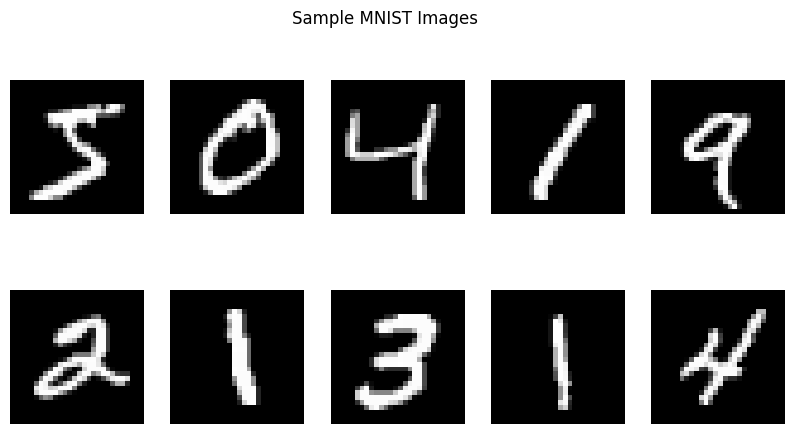

In [ ]:
# Display sample MNIST images
plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.axis("off")
plt.suptitle("Sample MNIST Images")
plt.show()

In [ ]:
# Normalize pixel values from [0, 255] to [-1, 1]

x_train = x_train.astype("float32")
x_train = (x_train - 127.5) / 127.5

# Add channel dimension
x_train = np.expand_dims(x_train, axis=-1)

print("Shape after reshaping:", x_train.shape)
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Shape after reshaping: (60000, 28, 28, 1)
Minimum pixel value: -1.0
Maximum pixel value: 1.0


In [ ]:
# Create batches for training

BATCH_SIZE = 128

train_dataset = tf.data.Dataset.from_tensor_slices(x_train)
train_dataset = train_dataset.shuffle(60000).batch(BATCH_SIZE)

print("Dataset prepared successfully.")
print("Batch size:", BATCH_SIZE)

Dataset prepared successfully.
Batch size: 128


In [ ]:
# ============================================
# PART B - GENERATOR
# ============================================
NOISE_DIM = 100
generator = keras.Sequential([
    layers.Input(shape=(NOISE_DIM,)),
    layers.Dense(7 * 7 * 128, use_bias=False),
    layers.BatchNormalization(),
    layers.LeakyReLU(),
    layers.Reshape((7, 7, 128)),
    layers.Conv2DTranspose(
        64, kernel_size=5, strides=2,
        padding="same", use_bias=False
    ),
    layers.BatchNormalization(),
    layers.LeakyReLU()
    layers.Conv2DTranspose(
        1, kernel_size=5, strides=2,
        padding="same", activation="tanh"
    )
])

generator.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       627,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 858,945 (3.28 MB)

 Trainable params: 846,273 (3.23 MB)

 Non-trainable params: 12,672 (49.50 KB)

Generated image shape: (1, 28, 28, 1)


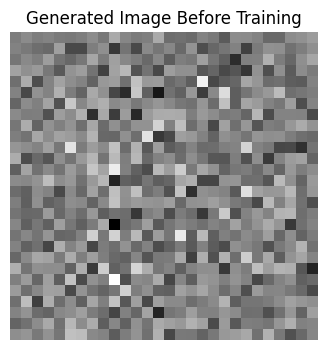

In [ ]:
# Generate image using random noise

random_noise = tf.random.normal([1, NOISE_DIM])

generated_image = generator(random_noise, training=False)

print("Generated image shape:", generated_image.shape)

plt.figure(figsize=(4, 4))
plt.imshow(generated_image[0, :, :, 0], cmap="gray")
plt.axis("off")
plt.title("Generated Image Before Training")
plt.show()

In [ ]:
# ============================================
# PART C - DISCRIMINATOR
# ============================================
discriminator = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(
        64, kernel_size=5, strides=2,
        padding="same"
    ),
    layers.LeakyReLU(),
    layers.Dropout(0.3),

    layers.Conv2D(
        128, kernel_size=5, strides=2,
        padding="same"
    ),
    layers.LeakyReLU(),
    layers.Dropout(0.3),

    layers.Flatten(),
    layers.Dense(1)
])

discriminator.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile the Discriminator

cross_entropy = keras.losses.BinaryCrossentropy(from_logits=True)

discriminator_optimizer = keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

discriminator.compile(
    optimizer=discriminator_optimizer,
    loss=cross_entropy,
    metrics=["accuracy"]
)

print("Discriminator compiled successfully.")

Discriminator compiled successfully.


In [ ]:
# ============================================
# GAN LOSS FUNCTIONS
# ============================================

generator_optimizer = keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(
        tf.ones_like(real_output),
        real_output
    )

    fake_loss = cross_entropy(
        tf.zeros_like(fake_output),
        fake_output
    )

    return real_loss + fake_loss


def generator_loss(fake_output):
    return cross_entropy(
        tf.ones_like(fake_output),
        fake_output
    )

print("GAN loss functions defined successfully.")

GAN loss functions defined successfully.


In [ ]:
# ============================================
# PART D - GAN TRAINING
# ============================================
EPOCHS = 20
NOISE_DIM = 100
gen_losses = []
disc_losses = []
@tf.function
def train_step(images):
    noise = tf.random.normal(
        [BATCH_SIZE, NOISE_DIM]
    )
    with tf.GradientTape() as gen_tape, \
         tf.GradientTape() as disc_tape:
        generated_images = generator(
            noise,
            training=True
        )
        real_output = discriminator(
            images,
            training=True
        )
        fake_output = discriminator(
            generated_images,
            training=True
        )
        g_loss = generator_loss(fake_output)

        d_loss = discriminator_loss(
            real_output,
            fake_output
        )
    gradients_of_generator = gen_tape.gradient(
        g_loss,
        generator.trainable_variables
    )
    gradients_of_discriminator = disc_tape.gradient(
        d_loss,
        discriminator.trainable_variables
    )
    generator_optimizer.apply_gradients(
        zip(
            gradients_of_generator,
            generator.trainable_variables
        )
    )
    discriminator_optimizer.apply_gradients(
        zip(
            gradients_of_discriminator,
            discriminator.trainable_variables
        )
    )
    return g_loss, d_loss

In [ ]:
# Train the GAN

for epoch in range(EPOCHS):

    total_g_loss = 0
    total_d_loss = 0
    batches = 0

    for image_batch in train_dataset:

        g_loss, d_loss = train_step(image_batch)

        total_g_loss += g_loss
        total_d_loss += d_loss
        batches += 1

    avg_g_loss = total_g_loss / batches
    avg_d_loss = total_d_loss / batches

    gen_losses.append(float(avg_g_loss))
    disc_losses.append(float(avg_d_loss))

    print(
        f"Epoch {epoch + 1}/{EPOCHS} "
        f"- Generator Loss: {avg_g_loss:.4f} "
        f"- Discriminator Loss: {avg_d_loss:.4f}"
    )

Epoch 1/20 - Generator Loss: 0.9173 - Discriminator Loss: 1.0781
Epoch 2/20 - Generator Loss: 0.8108 - Discriminator Loss: 1.2935
Epoch 3/20 - Generator Loss: 0.8336 - Discriminator Loss: 1.2633
Epoch 4/20 - Generator Loss: 0.9307 - Discriminator Loss: 1.1709
Epoch 5/20 - Generator Loss: 0.9900 - Discriminator Loss: 1.1503
Epoch 6/20 - Generator Loss: 0.9527 - Discriminator Loss: 1.2074
Epoch 7/20 - Generator Loss: 0.9182 - Discriminator Loss: 1.2247
Epoch 8/20 - Generator Loss: 0.9184 - Discriminator Loss: 1.2310
Epoch 9/20 - Generator Loss: 0.9090 - Discriminator Loss: 1.2355
Epoch 10/20 - Generator Loss: 0.9008 - Discriminator Loss: 1.2435
Epoch 11/20 - Generator Loss: 0.9059 - Discriminator Loss: 1.2396
Epoch 12/20 - Generator Loss: 0.9032 - Discriminator Loss: 1.2425
Epoch 13/20 - Generator Loss: 0.8987 - Discriminator Loss: 1.2429
Epoch 14/20 - Generator Loss: 0.9099 - Discriminator Loss: 1.2349
Epoch 15/20 - Generator Loss: 0.9244 - Discriminator Loss: 1.2312
Epoch 16/20 - Gener

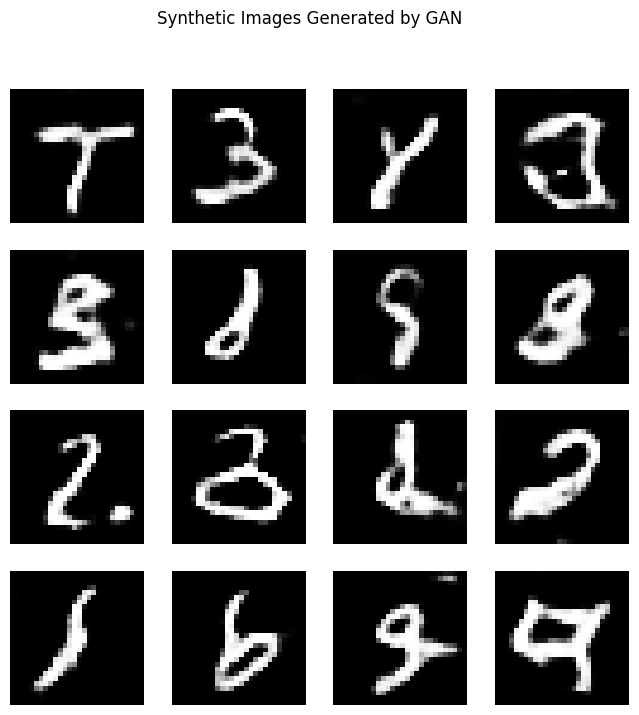

In [ ]:
# ============================================
# FINAL SYNTHETIC IMAGE GENERATION
# ============================================

NUM_IMAGES = 16

noise = tf.random.normal(
    [NUM_IMAGES, NOISE_DIM]
)

generated_images = generator(
    noise,
    training=False
)

plt.figure(figsize=(8, 8))

for i in range(NUM_IMAGES):
    plt.subplot(4, 4, i + 1)

    plt.imshow(
        generated_images[i, :, :, 0],
        cmap="gray"
    )

    plt.axis("off")

plt.suptitle("Synthetic Images Generated by GAN")
plt.show()

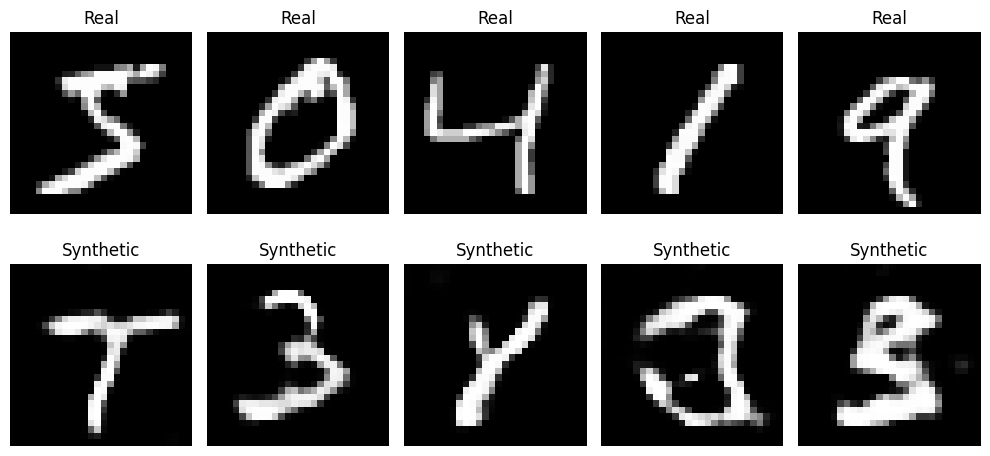

In [ ]:
# ============================================
# REAL VS SYNTHETIC IMAGES
# ============================================

plt.figure(figsize=(10, 5))

# Real images
for i in range(5):
    plt.subplot(2, 5, i + 1)
    plt.imshow(
        x_train[i, :, :, 0],
        cmap="gray"
    )
    plt.axis("off")
    plt.title("Real")

# Generated images
for i in range(5):
    plt.subplot(2, 5, i + 6)
    plt.imshow(
        generated_images[i, :, :, 0],
        cmap="gray"
    )
    plt.axis("off")
    plt.title("Synthetic")

plt.tight_layout()
plt.show()

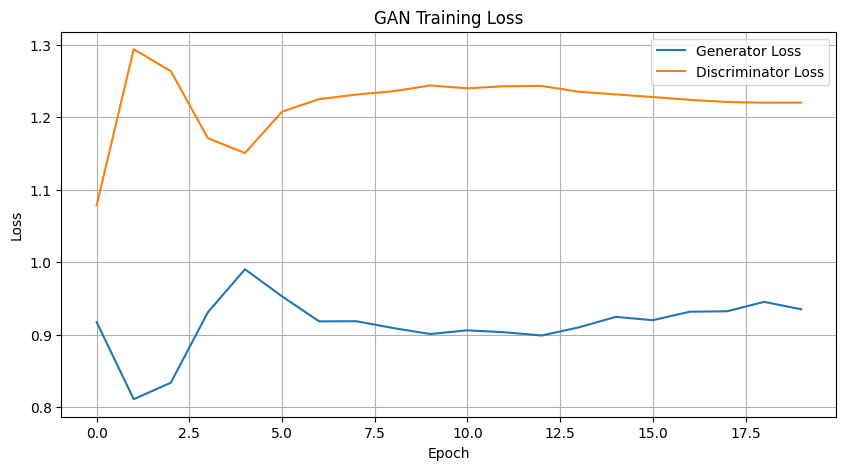

In [ ]:
# ============================================
# LOSS VISUALIZATION
# ============================================

plt.figure(figsize=(10, 5))

plt.plot(
    gen_losses,
    label="Generator Loss"
)

plt.plot(
    disc_losses,
    label="Discriminator Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GAN Training Loss")
plt.legend()
plt.grid()

plt.show()

Generated images saved as generated_gan_images.png


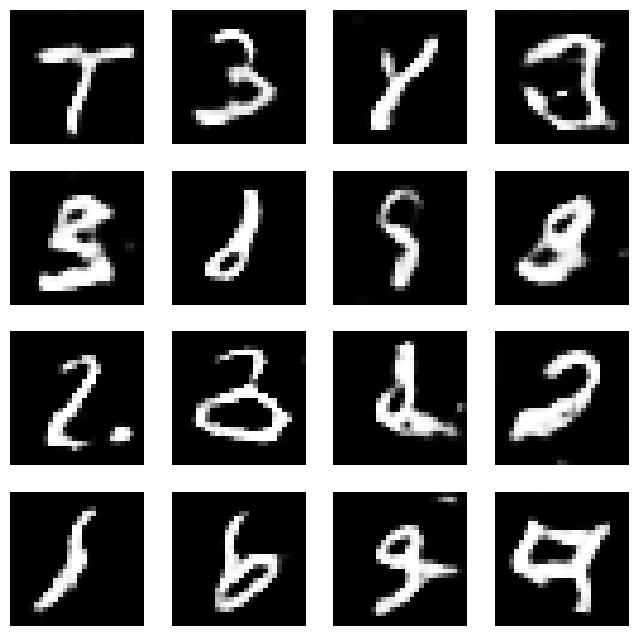

In [ ]:
# Save final generated images

plt.figure(figsize=(8, 8))

for i in range(NUM_IMAGES):
    plt.subplot(4, 4, i + 1)
    plt.imshow(
        generated_images[i, :, :, 0],
        cmap="gray"
    )
    plt.axis("off")

plt.savefig(
    "generated_gan_images.png",
    bbox_inches="tight"
)

print("Generated images saved as generated_gan_images.png")